# pyemread tutorial

This notebook runs the complete worked example of the paper *pyemread: A Python package for multi-line reading eye-movement experiments* on the example data distributed with the package: three English passages read aloud by three participants (1950138, 1950149, 1950168) while their eye movements were recorded with an EyeLink 1000 at 250 Hz (Gong & Shuai, 2023).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gtojty/pyemread/blob/master/examples/tutorial.ipynb)

The first cell installs the package and downloads the example data. It is needed only on Google Colab or in a fresh environment; run it from a terminal elsewhere (`pip install git+https://github.com/gtojty/pyemread.git`).

In [1]:
import importlib.util, os, subprocess, sys
if importlib.util.find_spec("pyemread") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/gtojty/pyemread.git"], check=True)
if not os.path.isdir("examples") and not os.path.isdir("oralReading"):
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/gtojty/pyemread.git", "pyemread_repo"], check=True)
    os.chdir("pyemread_repo")
EX = "examples" if os.path.isdir("examples") else "."
import pyemread
print("pyemread", pyemread.__version__)

pyemread 2.2.0


## Step 1. Stimulus bitmap and region file

`gen.praster` renders a passage, given as a list of lines, into a PNG bitmap and writes a region file with one row per word (its line number and bounding box). The font used here, DejaVu Sans Mono, ships with matplotlib.

In [2]:
import shutil
from pathlib import Path
import pandas as pd
from matplotlib import font_manager
from pyemread import cal, ext, ext_generic as eg, ext_robust, gen

OUT = Path("tutorial_output")
FONTPATH = font_manager.findfont("DejaVu Sans Mono")
with open(f"{EX}/textRasters/story01.txt", encoding="utf-8") as f:
    lines = [ln.strip() for ln in f if ln.strip() and not ln.startswith("#")]
gen.praster(direct=str(OUT / "stimuli"), fontpath=FONTPATH, st_pos="TopLeft",
            lang_type="English", text=lines, ID="story01")
pd.read_csv(OUT / "stimuli" / "story01.region.csv").head()

,Name,Language,WordID,Word,length,height,baseline,line_no,x1_pos,y1_pos,x2_pos,y2_pos,b_x1,b_y1,b_x2,b_y2
0,story01,English,1,Alex,4,14,86,1,215,89,259,103,215,71,259,125
1,story01,English,2,and,4,14,86,1,259,89,302,103,259,71,302,125
2,story01,English,3,Tim,4,14,86,1,302,89,345,103,302,71,345,125
3,story01,English,4,are,4,10,86,1,345,93,388,103,345,71,388,125
4,story01,English,5,lost.,6,14,86,1,388,89,453,103,388,71,453,125


## Step 2. Fixations, lines and words

`ext.process_subject` reads `<data>/<participant>/<participant>.asc`, extracts fixations and saccades for every trial, assigns each fixation to a text line and a word, and writes the tables that the measure computation reads. The recordings were made with the region files distributed with the data, which are used from here on.

In [3]:
DATA = OUT / "data"
SUBJECTS = ["1950138", "1950149", "1950168"]
REGIONS = ["story01.region.csv", "story02.region.csv", "story03.region.csv"]
DATA.mkdir(parents=True, exist_ok=True)
for r in REGIONS:
    shutil.copy(f"{EX}/oralReading/{r}", DATA / r)
for s in SUBJECTS:
    (DATA / s).mkdir(exist_ok=True)
    shutil.copy(f"{EX}/oralReading/{s}/{s}.asc", DATA / s)

for s in SUBJECTS:
    sac, crl_sac, fix, crl_fix = ext.process_subject(str(DATA), s, REGIONS)
fix.head()

Participant 1950138, trial 1, eye R: the SLICE and DIFF line assignments agree on only 51% of fixations; inspect this trial (gen.draw_line_assignment).


Participant 1950149, trial 1, eye L: the SLICE and DIFF line assignments agree on only 40% of fixations; inspect this trial (gen.draw_line_assignment).


Participant 1950149, trial 1, eye R: the SLICE and DIFF line assignments agree on only 65% of fixations; inspect this trial (gen.draw_line_assignment).


Participant 1950149, trial 2, eye L: the SLICE and DIFF line assignments agree on only 1% of fixations; inspect this trial (gen.draw_line_assignment).


Participant 1950149, trial 2, eye R: the SLICE and DIFF line assignments agree on only 1% of fixations; inspect this trial (gen.draw_line_assignment).


,subj,trial_id,trial_type,sampfreq,script,sessdate,srcfile,trialstart,trialend,tdur,...,eye,start_time,end_time,duration,x_pos,y_pos,pup_size,valid,line_no,region_no
0,1950168,1,story01,250,ET_Passa..._v2binoc,Thu Jan 14 20:30:29 2016,1950168.edf,570443,631164,60721,...,L,570443.0,570899.0,460.0,227.5,75.4,661.0,yes,1.0,1.0
1,1950168,1,story01,250,ET_Passa..._v2binoc,Thu Jan 14 20:30:29 2016,1950168.edf,570443,631164,60721,...,L,570951.0,571007.0,60.0,373.0,181.1,720.0,yes,3.0,28.0
2,1950168,1,story01,250,ET_Passa..._v2binoc,Thu Jan 14 20:30:29 2016,1950168.edf,570443,631164,60721,...,L,571043.0,571115.0,76.0,250.8,105.1,697.0,yes,1.0,1.0
3,1950168,1,story01,250,ET_Passa..._v2binoc,Thu Jan 14 20:30:29 2016,1950168.edf,570443,631164,60721,...,L,571143.0,571319.0,180.0,224.8,70.9,646.0,yes,1.0,1.0
4,1950168,1,story01,250,ET_Passa..._v2binoc,Thu Jan 14 20:30:29 2016,1950168.edf,570443,631164,60721,...,L,571335.0,571507.0,176.0,250.5,80.6,608.0,yes,1.0,1.0


## Step 3. Check the line assignment

`ext_robust.trial_report` compares, for every trial and eye, the default assignment (the *slice* algorithm) with the original pyemread heuristic (`DIFF`). The two methods fail in different situations, so a trial on which they disagree on more than 10% of fixations is flagged for visual inspection.

In [4]:
regions = ext.load_regions(str(DATA), REGIONS)
reports = []
for s in SUBJECTS:
    rep = ext_robust.trial_report(pd.read_csv(DATA / s / f"{s}_Fix.csv"), regions)
    rep.insert(0, "subj", s)
    reports.append(rep)
reports = pd.concat(reports, ignore_index=True)
reports[["subj", "trial_id", "trial_type", "eye", "agree_slice_diff", "flag"]]

,subj,trial_id,trial_type,eye,agree_slice_diff,flag
0,1950138,1,story01,L,0.975490,False
1,1950138,1,story01,R,0.514563,True
2,1950138,2,story02,L,0.931507,False
3,1950138,2,story02,R,0.958621,False
4,1950138,3,story03,L,0.953390,False
5,1950138,3,story03,R,0.969828,False
6,1950149,1,story01,L,0.403846,True
7,1950149,1,story01,R,0.656051,True
8,1950149,2,story02,L,0.005155,True
9,1950149,2,story02,R,0.005319,True


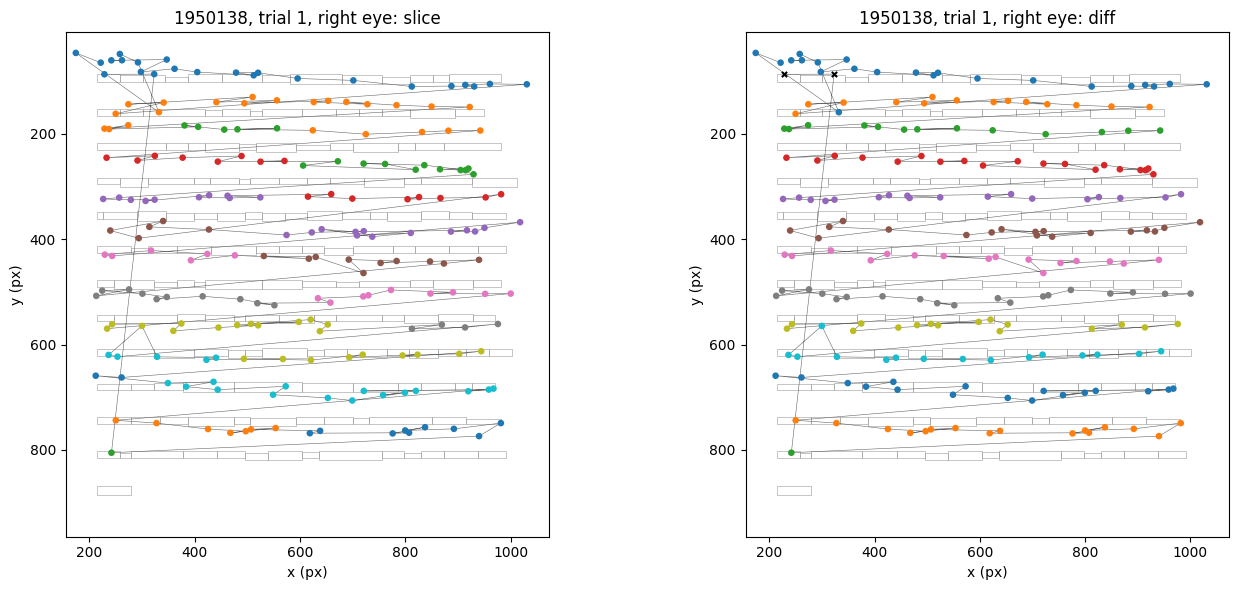

In [5]:
fix = pd.read_csv(DATA / "1950138" / "1950138_Fix.csv")
trial = fix[(fix.trial_id == 1) & (fix.eye == "R") & (fix.valid == "yes")]
gen.draw_line_assignment(trial, regions["story01"], title="1950138, trial 1, right eye: ");

In this trial the rows of fixations slope downwards. *slice* splits several rows between two lines, whereas the original heuristic assigns each row to one line, so the heuristic is used for this trial. The other flagged trials were inspected in the same way; in one of them (participant 1950149, trial 1, left eye) neither method was correct, and it is excluded below. The method can be chosen per trial:

In [6]:
ext.process_subject(str(DATA), "1950138", REGIONS,
                    classify_method={(1, "R"): "DIFF", "default": "SLICE"})
EXCLUDE = {("1950149", 1, "L")}

Participant 1950138, trial 1, eye R: the SLICE and DIFF line assignments agree on only 51% of fixations; inspect this trial (gen.draw_line_assignment).


## Step 4. Word-level measures

`cal.cal_write_em` returns (and writes) one row per word, trial and eye, with first-fixation duration (`ffixurt`), gaze duration (`fpurt`), regression-path duration (`rpurt`), total reading time (`tfurt`) and the other measures listed in the paper's Appendix A.

In [7]:
em = pd.concat([cal.cal_write_em(str(DATA), s, REGIONS) for s in SUBJECTS], ignore_index=True)
em = em[[(s, t, e) not in EXCLUDE for s, t, e in zip(em.subj, em.trial_id, em.eye)]]
em.to_csv(OUT / "word_measures.csv", index=False)
em[["subj", "trial_type", "eye", "region", "word", "ffixurt", "fpurt", "rpurt", "tfurt"]].head(10)

,subj,trial_type,eye,region,word,ffixurt,fpurt,rpurt,tfurt
0,1950138,story01,L,1,Alex,304.0,304.0,412.0,1196.0
1,1950138,story01,L,2,and,52.0,52.0,636.0,52.0
2,1950138,story01,L,3,Tim,NaN,NaN,NaN,640.0
3,1950138,story01,L,4,are,164.0,164.0,664.0,460.0
4,1950138,story01,L,5,lost.,328.0,328.0,328.0,1116.0
5,1950138,story01,L,6,Alex's,160.0,464.0,464.0,464.0
6,1950138,story01,L,7,wife,328.0,328.0,328.0,328.0
7,1950138,story01,L,8,recently,396.0,396.0,396.0,396.0
8,1950138,story01,L,9,passed,472.0,472.0,472.0,472.0
9,1950138,story01,L,10,away,NaN,NaN,NaN,NaN


The table imports directly into R for mixed-effects modelling, e.g. `lmer(log(fpurt) ~ word_length + (1|subj) + (1|word), data = d)`.

## Step 5. Data from other trackers

Recordings from other systems enter the same pipeline as a fixation table. `examples/bids_example` contains the right-eye data of participant 1950138 in Eye-Tracking-BIDS format. Fixations detected by the tracker are positioned with the samples, cut into trials with the recording's messages, and processed as above.

In [8]:
physio = f"{EX}/bids_example/sub-1950138/beh/sub-1950138_task-reading_recording-eye1_physio.tsv.gz"
samples, events, meta = eg.read_bids_eyetrack(physio)
trials = eg.trials_from_messages(events, r"TRIALID", r"TRIAL_RESULT", r"picture_name\s+(\S+?)\.png")
fix = eg.epoch(eg.bids_fixations(samples, events), trials)
eg.process_fixations(str(DATA), "bids-1950138", fix, REGIONS)
em_bids = cal.cal_write_em(str(DATA), "bids-1950138", REGIONS)
trials

,trial_id,start,end,trial_type
0,1,853040.0,906841.0,story01
1,2,915200.0,952585.0,story02
2,3,959020.0,1021493.0,story03


For screen-based recordings without tracker-detected fixations, `eg.detect_events` detects them in the raw samples (I-VT or I-DT, thresholds in degrees of visual angle):

In [9]:
_, fix_ivt = eg.detect_events(eg.epoch(samples, trials), method="IVT",
                              velocity_threshold=30, px_per_deg=40.5)
print(len(fix), "tracker fixations;", len(fix_ivt), "I-VT fixations")

590 tracker fixations; 560 I-VT fixations
